In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        # print(os.path.join(dirname, filename))
        pass

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [33]:
from pathlib import Path
import os

from tqdm import tqdm

import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score


import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn
from torch import optim

In [3]:
dir_path=Path().cwd().parent

data_dir_path=dir_path/'input/competitions/severstal-steel-defect-detection'
assert data_dir_path.exists()

images_train_dir=data_dir_path/'train_images'
images_val_dir=data_dir_path/'test_images'

In [5]:
random_state=4223

cuda_is_available = torch.cuda.is_available()
mps_is_available = torch.mps.is_available()


if cuda_is_available:
    device='cuda'
    print(torch.cuda.get_device_name())
elif mps_is_available:
    device='mps'
    print(torch._C._mps_get_name())
else:
    device='cpu'

device=torch.device(device)
use_amp=device.type=='cuda'

print('Device:', device)
print('Amp: ', use_amp)

Tesla T4
Device: cuda
Amp:  True


In [6]:
train_df=pd.read_csv(data_dir_path/'train.csv')
train_df.head()

,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


In [7]:
all_images=sorted(os.listdir(images_train_dir))
images_df = pd.DataFrame({
    "ImageId": sorted(all_images)
})

images_df["has_defect"] = images_df["ImageId"].isin(train_df['ImageId']).astype(int)


images_df=images_df.merge(
    train_df,
    on='ImageId',
    how='left'
)

images_df['ClassId']=images_df['ClassId'].fillna(0)
images_df['EncodedPixels']=images_df['EncodedPixels'].fillna('0')

images_df.head()

,ImageId,has_defect,ClassId,EncodedPixels
0,0002cc93b.jpg,1,1.0,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,00031f466.jpg,0,0.0,0
2,000418bfc.jpg,0,0.0,0
3,000789191.jpg,0,0.0,0
4,0007a71bf.jpg,1,3.0,18661 28 18863 82 19091 110 19347 110 19603 11...


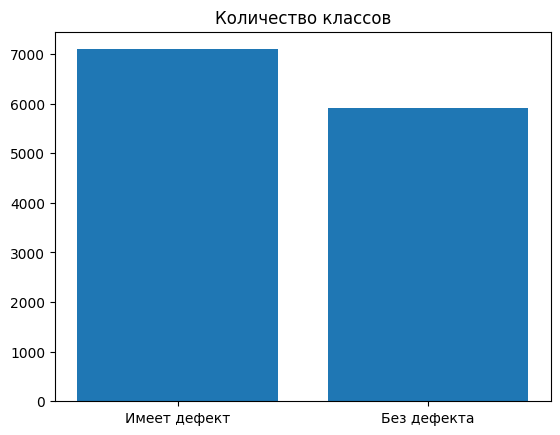

In [8]:
target_counts=images_df.has_defect.value_counts()

plt.title('Количество классов')
plt.bar(['Имеет дефект', 'Без дефекта'], target_counts)
plt.show()

In [9]:
df_train, df_val = train_test_split(images_df, test_size=0.2, stratify=images_df.ClassId, random_state=random_state)

print(f'Train size: {df_train.shape}')
print(f'Val size: {df_val.shape}')

Train size: (10397, 4)
Val size: (2600, 4)


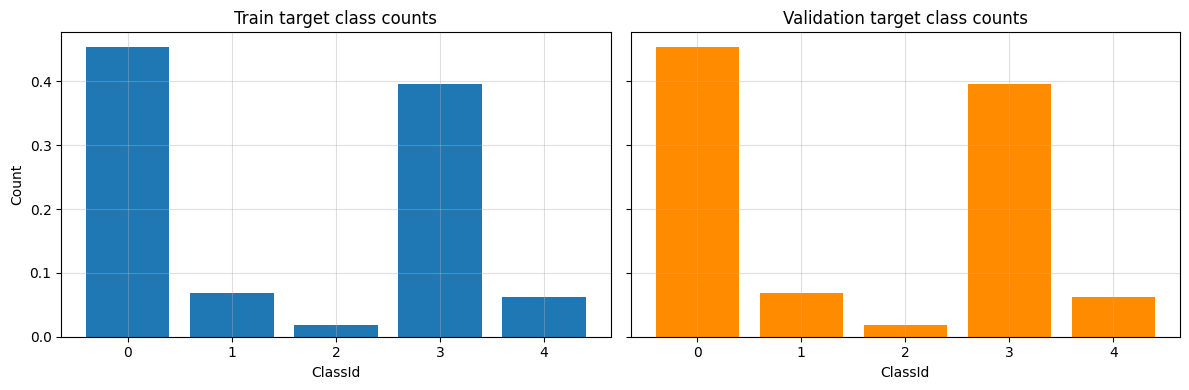

In [10]:
train_target_counts = df_train.ClassId.value_counts(normalize=True).sort_index()
val_target_counts = df_val.ClassId.value_counts(normalize=True).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].bar(train_target_counts.index, train_target_counts)
axes[0].set_title('Train target class counts')
axes[0].set_xlabel('ClassId')
axes[0].set_ylabel('Count')
axes[0].grid(alpha=0.4)

axes[1].bar(val_target_counts.index, val_target_counts, color='darkorange')
axes[1].set_title('Validation target class counts')
axes[1].set_xlabel('ClassId')
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

In [11]:
class ClassificationDataset(Dataset):
    def __init__(self, data_df, images_dir):
        self.data_df=data_df
        self.images_dir=images_dir

    def __len__(self):
        return len(self.data_df)

    def __getitem__(self, index):
        row=self.data_df.iloc[index]

        img_path=self.images_dir/row.ImageId

        img=cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        img=cv2.resize(img, (512, 128))

        img=torch.tensor(img) / 255.0
        img=img.unsqueeze(0)

        label = torch.tensor(row.has_defect.item(), dtype=torch.float)
        return img, label

In [85]:
batch_size=128

In [86]:
train_dataset=ClassificationDataset(df_train, images_train_dir)
val_dataset=ClassificationDataset(df_val, images_train_dir)


train_dataloader=DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=4,
    persistent_workers=True,
    prefetch_factor=2,

)

val_dataloader=DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True,
    num_workers=4,
    persistent_workers=True,
    prefetch_factor=2,
    
)

In [76]:
def training(train_dataloader, val_dataloader, model, optimizer, loss_fn, scheduler, gradient_scaler, device, use_amp=False, epochs=10, logs=True, checkpoints=True, save_dir=Path().cwd(),model_prefix='model') -> dict[str]:
    history = {
    'epoch': [],
    'train_loss': [],
    'val_loss': [],
    'train_precision': [],
    'val_precision': [],
    'train_recall': [],
    'val_recall': [],
    'train_f1': [],
    'val_f1': [],
    'lr': []
    }

    save_dir.mkdir(exist_ok=True)

    for epoch in range(epochs):
        train_running_loss = 0.0
        val_running_loss = 0.0

        train_preds, train_targets = [], []
        val_preds, val_targets = [], []

        model.train()

        for img, labels in tqdm(train_dataloader):
            optimizer.zero_grad(set_to_none=True)

            img = img.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                predict = model(img)
                logits = predict.squeeze(1)
                loss = loss_fn(logits, labels)

            gradient_scaler.scale(loss).backward()
            gradient_scaler.step(optimizer)
            gradient_scaler.update()

            train_running_loss += loss.item() * img.size(0)

            preds = (logits.detach() > 0).int()
    
            train_preds.extend(preds.cpu().numpy())
            train_targets.extend(labels.cpu().numpy())

        # Validation
        model.eval()
    
        with torch.no_grad():
            for img, labels in tqdm(val_dataloader):
                img = img.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
    
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    predict = model(img)
                    logits = predict.squeeze(1)
                    loss = loss_fn(logits, labels)
    
                val_running_loss += loss.item() * img.size(0)
    
                preds = (logits > 0).int()
    
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())
    
        # Loss
        train_loss = train_running_loss / len(train_targets)
        val_loss = val_running_loss / len(val_targets)
    
        # Metrics
        train_precision = precision_score(train_targets, train_preds, zero_division=0)
        val_precision = precision_score(val_targets, val_preds, zero_division=0)
    
        train_recall = recall_score(train_targets, train_preds, zero_division=0)
        val_recall = recall_score(val_targets, val_preds, zero_division=0)

        train_f1 = f1_score(train_targets, train_preds, zero_division=0)
        val_f1 = f1_score(val_targets, val_preds, zero_division=0)
    
        scheduler.step(val_loss)
    
        # History
        history['epoch'].append(epoch + 1)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_precision'].append(train_precision)
        history['val_precision'].append(val_precision)
        history['train_recall'].append(train_recall)
        history['val_recall'].append(val_recall)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        if logs:
            print(f'Epoch {epoch + 1}')
            print(f'Train loss = {train_loss:.4f} | Val loss = {val_loss:.4f}')
            print(f'Precision: {train_precision:.4f} | {val_precision:.4f}')
            print(f'Recall:    {train_recall:.4f} | {val_recall:.4f}')
            print(f'F1 score:  {train_f1:.4f} | {val_f1:.4f}')
            print(f"LR = {optimizer.param_groups[0]['lr']:.2e}")
            print('-' * 40)

        if checkpoints:
            torch.save(model.state_dict(), save_dir/f'{model_prefix}_epoch_{epoch+1}.pth')

    return {
        'history': history,
        'final_model': model
    }

## Convolution Neural Network

In [87]:
class CnnClassifier(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()

        self.features=nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_features=16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_features=32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(2),
            nn.Flatten()
        )

        self.fcn=nn.Sequential(
            nn.Linear(64*2*2, 128),
            nn.Dropout(0.2),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        features_extracted=self.features(x)

        out = self.fcn(features_extracted)
        return out

In [89]:
model = CnnClassifier().to(device)

optimizer=optim.Adam(model.parameters(), lr=0.002)
loss_fn=nn.BCEWithLogitsLoss()

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

scaler = torch.amp.GradScaler(device, enabled=use_amp)

In [90]:
results=training(
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    
    model=model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    scheduler=scheduler,
    
    gradient_scaler=scaler,
    device=device,
    use_amp=use_amp,
    
    epochs=40,
    logs=True,

    checkpoints=True,
    save_dir=Path().cwd()/'saved_models',
    model_prefix='baseline_cnn'
)

100%|██████████| 21/21 [00:05<00:00,  4.14it/s]


Epoch 1
Train loss = 0.5242 | Val loss = 0.5229
Precision: 0.7230 | 0.6544
Recall:    0.8187 | 0.9394
F1 score:  0.7679 | 0.7714
LR = 2.00e-03
----------------------------------------


100%|██████████| 21/21 [00:04<00:00,  4.38it/s]


Epoch 2
Train loss = 0.4493 | Val loss = 0.5020
Precision: 0.7926 | 0.6970
Recall:    0.7985 | 0.9288
F1 score:  0.7955 | 0.7964
LR = 2.00e-03
----------------------------------------


100%|██████████| 21/21 [00:04<00:00,  4.33it/s]


Epoch 3
Train loss = 0.4144 | Val loss = 0.4620
Precision: 0.8140 | 0.7063
Recall:    0.8200 | 0.9507
F1 score:  0.8170 | 0.8105
LR = 2.00e-03
----------------------------------------


... (70 outputs left out)

100%|██████████| 21/21 [00:04<00:00,  4.48it/s]


Epoch 39
Train loss = 0.1707 | Val loss = 0.1949
Precision: 0.9237 | 0.9152
Recall:    0.9475 | 0.9507
F1 score:  0.9355 | 0.9326
LR = 1.25e-04
----------------------------------------


100%|██████████| 21/21 [00:04<00:00,  4.50it/s]


Epoch 40
Train loss = 0.1726 | Val loss = 0.1958
Precision: 0.9269 | 0.9068
Recall:    0.9475 | 0.9457
F1 score:  0.9371 | 0.9258
LR = 1.25e-04
----------------------------------------


In [91]:
model=results['final_model']
history=results['history']

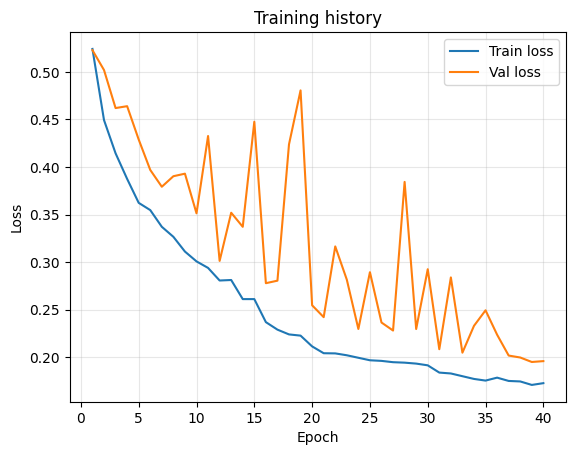

In [92]:
history_df = pd.DataFrame(history)

plt.plot(history_df['epoch'], history_df['train_loss'], label='Train loss')
plt.plot(history_df['epoch'], history_df['val_loss'], label='Val loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

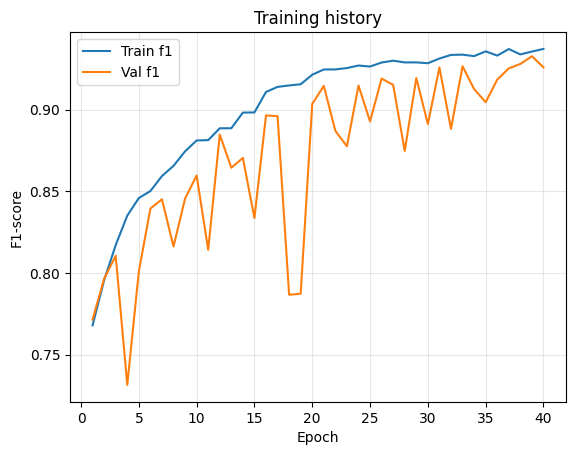

In [93]:
history_df = pd.DataFrame(history)

plt.plot(history_df['epoch'], history_df['train_f1'], label='Train f1')
plt.plot(history_df['epoch'], history_df['val_f1'], label='Val f1')

plt.xlabel('Epoch')
plt.ylabel('F1-score')
plt.title('Training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

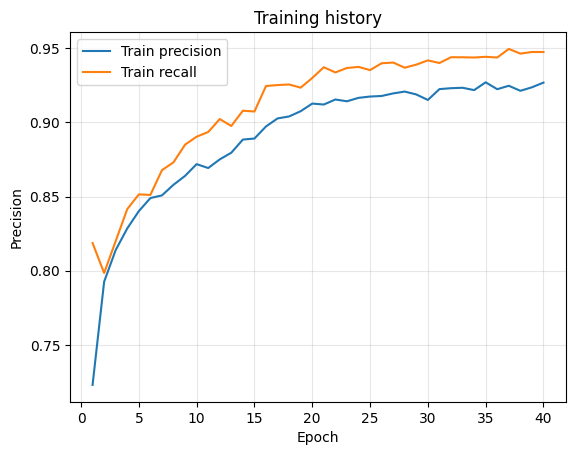

In [94]:
history_df = pd.DataFrame(history)

plt.plot(history_df['epoch'], history_df['train_precision'], label='Train precision')
plt.plot(history_df['epoch'], history_df['train_recall'], label='Train recall')

plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.title('Training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

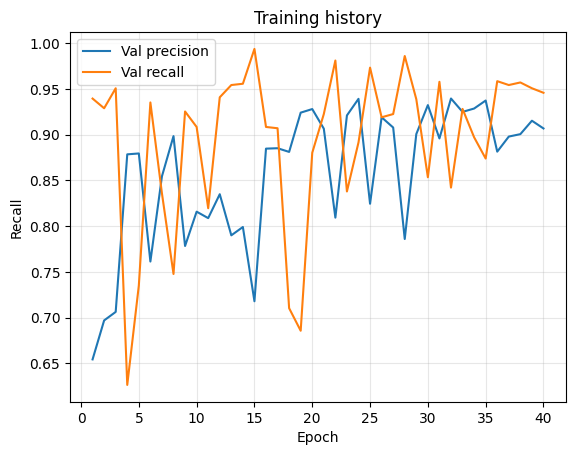

In [95]:
history_df = pd.DataFrame(history)

plt.plot(history_df['epoch'], history_df['val_precision'], label='Val precision')
plt.plot(history_df['epoch'], history_df['val_recall'], label='Val recall')

plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.title('Training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## ResNet

In [28]:
model.eval()

example_input = torch.randn(1, 1, 128, 512)

model_save_dir=dir_path/'models'
model_save_dir.mkdir(exist_ok=True)

torch.onnx.export(
    model.to('cpu'),
    (example_input,),
    model_save_dir/"cnn_classifier_v1.onnx",
    input_names=["images"],
    output_names=["logits"],
    dynamo=True
)

ModuleNotFoundError: No module named 'onnxscript'